(sec-3)=
# 3. Revisión sistemática del estado del arte

En esta sección se extiende la revisión del Entregable 1, que identificó los tres modelos base, para seleccionar con un puntaje explícito el Top 10 de modelos de Deep Learning, describirlos uno por uno, compararlos críticamente y formular el *gap* de investigación. La revisión del Entregable 1 se conserva completa en su cuaderno; aquí se resume lo necesario y se documenta lo nuevo: la actualización de las cadenas, una cadena ampliada por familias de modelos, la búsqueda transversal de mecanismos, dos campos nuevos de la hoja de extracción (código público y líneas base ajustadas) y el puntaje de selección.

(sec-3-1)=
## 3.1 Estrategia de búsqueda

**Cadenas, bases y fechas.** El Entregable 1 ejecutó tres cadenas sobre título y resumen, de 2019 a 2026: C1, general; C2, centrada en los ataques del conjunto de datos, y C3, sobre el uso de UAVIDS-2025. Se corrieron en OpenAlex y arXiv el 3 de noviembre de 2026 y en IEEE Xplore, Scopus y Web of Science el 4 de noviembre, con el acceso de la biblioteca de la Universidad del Norte, y se completaron con una verificación de cobertura de sinónimos el 5 de noviembre. Para este entregable se agregan, el 12 de noviembre de 2026 en OpenAlex y arXiv, la repetición de C1 a C3, para captar lo publicado después; C4, que amplía el concepto de método con las familias candidatas al Top 10, y cuatro cadenas transversales, T1 a T4, que buscan los mecanismos en otras modalidades, como pide el enunciado. El 13 de noviembre, con el mismo acceso institucional, las cadenas transversales T1 a T4 se corrieron también en Scopus y en Web of Science, de modo que cumplen el mínimo de dos bases principales que pide el enunciado; IEEE Xplore no se usó para ellas, porque el primer intento devolvió un error del servidor y el mínimo ya se cumplía con las otras dos. La repetición de C1 a C3 no se corrió en esas bases, porque las mismas cadenas ya se corrieron allí el 4 de noviembre, ni tampoco C4, que es una cadena complementaria: en OpenAlex y arXiv aportó 87 de los 94 registros nuevos, pero ninguno de sus estudios elegibles tuvo texto completo accesible, de modo que no modificó los estudios incluidos. En la tabla de conteos, la raya indica una cadena que no se corrió en esa base. Las consultas exactas, con la sintaxis de cada base, están en `literatura/consultas_e2_wos_scopus_ieee.md`.

| Cadena | Consulta | Periodo |
|---|---|---|
| C1 | (drone OR UAV OR "unmanned aerial" OR FANET) AND ("intrusion detection" OR "attack detection") AND ("deep learning" OR "neural network" OR CNN OR LSTM OR MLP) | 2019–2026 |
| C2 | (drone OR UAV OR "unmanned aerial" OR FANET) AND (swarm OR "ad hoc" OR "network traffic") AND (blackhole OR wormhole OR sybil OR flooding OR cyberattack) AND ("deep learning" OR "neural network" OR CNN OR LSTM OR MLP) | 2019–2026 |
| C3 | UAVIDS OR "UAVIDS-2025" | 2019–2026 |
| C4 | (drone OR UAV OR "unmanned aerial" OR FANET OR "Internet of Drones") AND ("intrusion detection" OR "attack detection" OR "anomaly detection") AND (GRU OR "gated recurrent" OR BiLSTM OR "bidirectional LSTM" OR transformer OR TabNet OR "Kolmogorov-Arnold" OR autoencoder OR "deep belief" OR ResNet OR residual OR "CNN-LSTM" OR "graph neural" OR "temporal convolutional" OR mamba OR "state space") | 2019–2026 |
| T1 | ("supervised contrastive" OR "contrastive learning") AND (image OR "computer vision" OR visual) AND (transfer OR adaptation) | 2018–2026 |
| T2 | ("mixture of experts" OR "gated experts") AND ("natural language" OR "language model" OR vision) AND (transfer OR adaptation) | 2018–2026 |
| T3 | ("domain generalization" OR "invariant risk minimization" OR "distributionally robust") AND (image OR vision OR speech) AND (transfer OR adaptation) | 2018–2026 |
| T4 | ("Kolmogorov-Arnold" OR "feature tokenizer" OR "tabular transformer") AND ("time series" OR vision OR image OR language) AND (transfer OR adaptation) | 2018–2026 |

**Periodo.** Las cadenas cubren los últimos ocho años. Los trabajos fundacionales anteriores, como Elman (1990) para la RNN o Hinton et al. (2006) para la DBN, se citan como fuente de cada arquitectura y no entran al conteo de frecuencia, porque no abordan el problema.

**Criterios de inclusión y exclusión.** Son los del Entregable 1: se incluye un estudio si detecta o clasifica intrusiones o ataques en redes o sistemas de drones a partir de datos tabulares de tráfico o del sistema, usa Deep Learning, reporta métricas verificables y compara contra al menos un modelo de Deep Learning; se excluye si no es un estudio primario o si trabaja con imágenes, señales de radio, solo suplantación de GPS o anomalías de vuelo. La calidad de la fuente se registra con el cuartil SJR 2025 de SCImago (2026), y la disponibilidad de código y de detalles para reproducir, en los campos nuevos de la hoja de extracción.

In [15]:
import csv
LIT1, LIT2 = D.E1 / "literatura", RAIZ_E2 / "literatura"
leer_csv = lambda ruta: list(csv.DictReader(ruta.open(encoding="utf-8-sig")))
REG_E1, COB_E1, REG_E2 = leer_csv(LIT1 / "registros_depurados.csv"), leer_csv(LIT1 / "cribado_cobertura_sinonimos.csv"), leer_csv(LIT2 / "registros_nuevos_e2.csv")
EXT = leer_csv(LIT1 / "extraccion_estudios.csv") + leer_csv(LIT2 / "extraccion_estudios_e2.csv")
REPRO = {r["doi"]: r for r in leer_csv(LIT2 / "reproducibilidad_estudios.csv")}
resumen_e2 = json.loads((LIT2 / "exportaciones" / "2026-11-12_resumen_e2.json").read_text(encoding="utf-8"))
conteo_e2 = pd.DataFrame(resumen_e2["resultados"]).pivot(index="fuente", columns="cadena", values="total")
conteo_bases_e2 = pd.DataFrame(json.loads((LIT2 / "exportaciones" / "2026-11-13_conteos_scopus_wos_e2.json").read_text(encoding="utf-8"))["resultados"]).pivot(index="fuente", columns="cadena", values="total")
conteo_e2 = pd.concat([conteo_e2, conteo_bases_e2])
conteo_e1 = pd.DataFrame({"C1": [323, 11, 481, 132, 523], "C2": [40, 3, 40, 11, 18], "C3": [220, 29, 81, 16, 26]}, index=["OpenAlex", "arXiv", "IEEE Xplore", "Web of Science", "Scopus"])
conteos = pd.concat({"Entregable 1 (3 y 4 de noviembre)": conteo_e1, "Entregable 2 (12 y 13 de noviembre)": conteo_e2}, axis=1).reindex(["OpenAlex", "arXiv", "IEEE Xplore", "Scopus", "Web of Science"])
tabla(conteos.reset_index(names="Base").map(lambda v: "—" if pd.isna(v) else (f"{int(v):,}".replace(",", " ") if isinstance(v, (int, float)) else v)), indice=False)
elegibles_e1 = [r for r in REG_E1 if r["cribado"] == "elegible"]
cob_eleg = [r for r in COB_E1 if r["decision"] in ("elegible", "dudoso")]
PRISMA = {"exportados_e1": 583 + 42 + 602 + 567 + 159, "depurados_e1": len(REG_E1), "filtro_e1": sum(r["cribado"] == "" for r in REG_E1), "excluidos_e1": sum(r["cribado"] == "excluido" for r in REG_E1),
          "elegibles_e1": len(elegibles_e1), "no_recuperados_e1": sum(r["texto_completo"] == "no recuperado" for r in elegibles_e1), "cob_elegibles": len(cob_eleg), "cob_incluidos": 4,
          "unicos_e2": 860, "ya_revisados_e2": 860 - len(REG_E2), "nuevos_e2": len(REG_E2), "filtro_e2": sum(r["cribado"] == "" for r in REG_E2), "excluidos_e2": sum(r["cribado"] == "excluido" for r in REG_E2),
          "elegibles_e2": sum(r["cribado"] in ("elegible", "dudoso") for r in REG_E2), "no_recuperados_e2": sum(r["texto_completo"] == "no recuperado" for r in REG_E2),
          "incluidos_e2": sum(r["texto_completo"] == "incluido" for r in REG_E2), "incluidos": len(EXT)}
PRISMA["evaluados_e1"] = PRISMA["elegibles_e1"] - PRISMA["no_recuperados_e1"]
PRISMA["incluidos_e1_bases"] = 38

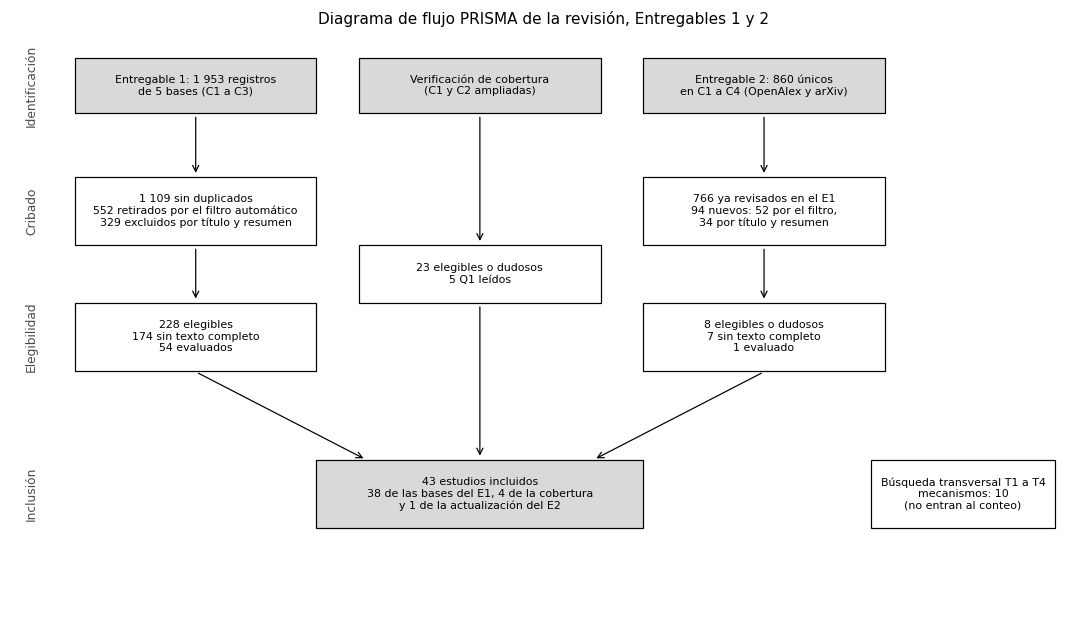

In [16]:
fig, eje = plt.subplots(figsize=(12.5, 6.8))
eje.axis("off")
eje.set(xlim=(0, 15), ylim=(0, 11))
def caja(x, yy, texto, ancho=3.4, alto=1.05, relleno="white"):
    eje.add_patch(plt.Rectangle((x - ancho / 2, yy - alto / 2), ancho, alto, facecolor=relleno, edgecolor=NEGRO, lw=0.8))
    eje.text(x, yy, texto, ha="center", va="center", fontsize=7.2)
def flecha(a, b):
    eje.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color=NEGRO, lw=0.8))
P = PRISMA
for etiqueta_fase, yy in (("Identificación", 10), ("Cribado", 7.6), ("Elegibilidad", 5.2), ("Inclusión", 2.2)):
    eje.text(0.2, yy, etiqueta_fase, rotation=90, va="center", fontsize=8, color=GRIS_OSCURO)
caja(2.6, 10, f"Entregable 1: {P['exportados_e1']:,} registros\nde 5 bases (C1 a C3)".replace(",", " "), relleno=GRIS_CLARO)
caja(2.6, 7.6, f"{P['depurados_e1']:,} sin duplicados\n{P['filtro_e1']} retirados por el filtro automático\n{P['excluidos_e1']} excluidos por título y resumen".replace(",", " "), alto=1.3)
caja(2.6, 5.2, f"{P['elegibles_e1']} elegibles\n{P['no_recuperados_e1']} sin texto completo\n{P['evaluados_e1']} evaluados", alto=1.3)
caja(6.6, 10, f"Verificación de cobertura\n(C1 y C2 ampliadas)", relleno=GRIS_CLARO)
caja(6.6, 6.4, f"{P['cob_elegibles']} elegibles o dudosos\n5 Q1 leídos", alto=1.1)
caja(10.6, 10, f"Entregable 2: {P['unicos_e2']} únicos\nen C1 a C4 (OpenAlex y arXiv)", relleno=GRIS_CLARO)
caja(10.6, 7.6, f"{P['ya_revisados_e2']} ya revisados en el E1\n{P['nuevos_e2']} nuevos: {P['filtro_e2']} por el filtro,\n{P['excluidos_e2']} por título y resumen", alto=1.3)
caja(10.6, 5.2, f"{P['elegibles_e2']} elegibles o dudosos\n{P['no_recuperados_e2']} sin texto completo\n{P['incluidos_e2']} evaluado", alto=1.3)
caja(6.6, 2.2, f"{P['incluidos']} estudios incluidos\n{P['incluidos_e1_bases']} de las bases del E1, {P['cob_incluidos']} de la cobertura\ny {P['incluidos_e2']} de la actualización del E2", ancho=4.6, alto=1.3, relleno=GRIS_CLARO)
caja(13.4, 2.2, f"Búsqueda transversal T1 a T4\nmecanismos: {len(leer_csv(LIT2 / 'mecanismos_transferibles.csv'))}\n(no entran al conteo)", ancho=2.6, alto=1.3)
for a, b in (((2.6, 9.45), (2.6, 8.27)), ((2.6, 6.93), (2.6, 5.87)), ((2.6, 4.53), (5.0, 2.85)), ((6.6, 9.45), (6.6, 6.97)), ((6.6, 5.83), (6.6, 2.87)),
             ((10.6, 9.45), (10.6, 8.27)), ((10.6, 6.93), (10.6, 5.87)), ((10.6, 4.53), (8.2, 2.85))):
    flecha(a, b)
eje.set_title("Diagrama de flujo PRISMA de la revisión, Entregables 1 y 2", fontsize=10)
plt.show()

**Interpretación.** La actualización del 12 de noviembre devolvió en C1 y C2 los mismos conteos del 3 de noviembre, de modo que en nueve días no aparecieron estudios nuevos con las cadenas originales. Lo nuevo vino de C3 y de la cadena ampliada C4: de 860 registros únicos, 766 ya se habían revisado en el Entregable 1 y 94 eran nuevos; el filtro automático retiró 52, el cribado por título y resumen excluyó 34, casi todos por tratar anomalías de vuelo, de sensores o de imágenes, y quedaron 5 elegibles y 3 dudosos. De esos 8, solo uno tenía texto completo accesible (Tasfia et al., 2026), que se incluye; los otros 7 quedan sin evaluar. El total de estudios incluidos pasa de 42 a 43.

Hay que tener en cuenta que entre los no recuperados hay dos estudios relevantes para este benchmark: Di et al. (2026), que según su resumen comparan FT-Transformer, MLP y árboles en IDS de UAV con 5 semillas y corrección de Holm, y el de TopoXNet, que usa UAVIDS-2025. Es decir, la revisión tiene un sesgo de acceso, que ya declaró el Entregable 1, y que aquí podría afectar el último puesto del Top 10, como se cuantifica en la sección 3.2.

Por tal motivo, se mantiene la regla del Entregable 1, según la cual solo cuentan los estudios evaluados a texto completo, y se reporta la sensibilidad del Top 10 a incluir los no recuperados con lo que dicen sus resúmenes. Las decisiones de cada registro están en `literatura/registros_nuevos_e2.csv`.

**Quién realizó la selección.** Al ser un trabajo de autor único, hubo un solo revisor, de modo que no aplica el acuerdo de Cohen entre revisores; es una limitación frente a un cribado doble. El cribado y la extracción se hicieron con apoyo de un asistente de inteligencia artificial (Claude, de Anthropic) bajo la supervisión del autor, con búsqueda dirigida de las tablas y los pasajes de cada texto.

**Hoja de extracción.** La hoja tiene los campos fijos que pide el enunciado: arquitectura, dataset, partición, métricas, repeticiones o semillas, pruebas estadísticas, código público y líneas base ajustadas. Los dos últimos son nuevos en este entregable: el código se buscó en el texto completo de cada estudio, con una revisión manual de cada enlace hallado, y se considera ajustada una línea base solo si el estudio declara haberla ajustado con un procedimiento comparable al del modelo propuesto.

In [17]:
import unicodedata

METADATOS = json.loads((LIT1 / "estudios_metadatos.json").read_text(encoding="utf-8"))
METADATOS["10.22266/ijies2025.0531.33"]["autores"] = ["Aws Hamed Hamad", "Noor Khalid Hussein", "Abdulrahman M. Abdulghani"]
METADATOS["sin-doi:dragon"]["autores"] = ["P. SureshBabu", "M. Geetha"]
METADATOS["10.1007/s10207-026-01353-8"] = {"autores": ["Rifa Tasfia", "Anitha Chennamaneni", "Abhijit Kumar Nag"], "anio": 2026, "titulo": "Revisiting adversarial robustness in NIDS: a multi-dataset evaluation of test-time evasion attacks",
                                           "fuente": "International Journal of Information Security", "volumen": "25", "numero": None, "paginas": "184", "tipo": "article"}
COMPUESTOS = {"Canan Batur Şahin": ("Batur Şahin", "Canan")}
PARTICULAS = {"van", "von", "de", "der", "den", "del", "da", "du", "le", "la"}
def partes_nombre(nombre):
    # Apellido y nombres; las partículas (van, de, von...) van con el apellido: Bart van Merriënboer → van Merriënboer, Bart
    if nombre in COMPUESTOS:
        return COMPUESTOS[nombre]
    f = nombre.replace("‐", "-").split()
    i = len(f) - 2
    while i >= 1 and f[i].lower() in PARTICULAS:
        i -= 1
    return " ".join(f[i + 1:]), " ".join(f[:i + 1])
def cita_base(doi):
    m = METADATOS[doi]
    a = [partes_nombre(x)[0] for x in m["autores"]]
    autor = a[0] if len(a) == 1 else f"{a[0]} y {a[1]}" if len(a) == 2 else f"{a[0]} et al."
    return f"{autor} ({m['anio']})"
def clave_orden(t):
    # Clave de orden alfabético sin tildes ni signos diacríticos (la ı turca se ordena como i)
    return "".join(c for c in unicodedata.normalize("NFKD", t.lower().replace("ı", "i")) if not unicodedata.combining(c))
def iniciales(nombres):
    return " ".join("-".join(p[0] + "." for p in n.split("-") if p) for n in nombres.split())
def autor_apa(apellido, nombres):
    return f"{apellido}, {iniciales(nombres)}" if nombres.strip() else apellido
def orden_autores(doi):
    # Mismo orden que la lista de referencias: autores completos y luego título
    m = METADATOS[doi]
    return clave_orden(", ".join(autor_apa(a, n) for a, n in map(partes_nombre, m["autores"])) + " " + m["titulo"])
SUFIJO = {}
for base in {cita_base(e["doi"]) for e in EXT}:
    iguales = sorted((e["doi"] for e in EXT if cita_base(e["doi"]) == base), key=orden_autores)
    if len(iguales) > 1:
        SUFIJO.update({d: "abcdef"[i] for i, d in enumerate(iguales)})
citar = lambda doi: cita_base(doi)[:-1] + SUFIJO.get(doi, "") + ")"
agrupa = lambda p: "por sesión" in p or "por nodo" in p
hoja = pd.DataFrame([{"Estudio": citar(e["doi"]), "Arquitecturas de DL": e["modelos"], "Dataset": e["dataset"], "Partición": e["particion"], "Métricas y valores": e["valores"],
                      "Repeticiones o semillas": e["repeticiones"], "Dispersión": e["dispersion"], "Prueba estadística": e["prueba"],
                      "Código público": REPRO[e["doi"]]["codigo_publico"], "Líneas base ajustadas": REPRO[e["doi"]]["baselines_ajustados"],
                      "Riesgo de fuga": "No evaluable" if e["particion"] == "no identificada" else ("Menor: agrupa filas relacionadas" if agrupa(e["particion"]) else "Alto: no agrupa filas relacionadas")}
                     for e in sorted(EXT, key=lambda e: cita_base(e["doi"]).lower())])
hoja.to_csv(LIT2 / "hoja_extraccion_e2.csv", index=False, encoding="utf-8-sig")
with pd.option_context("display.max_colwidth", 70):
    tabla(hoja.drop(columns=["Métricas y valores"]))
n = len(hoja)
calidad_lit = {"con código": int((hoja["Código público"] == "sí").sum()), "sin texto": int((hoja["Código público"] == "no verificable").sum()),
               "datos públicos": sum(REPRO[e["doi"]]["datos_publicos"] == "sí" for e in EXT), "agrupan": int(hoja["Riesgo de fuga"].str.startswith("Menor").sum()),
               "sin repeticiones": int((hoja["Repeticiones o semillas"] == "no reportadas").sum()), "con dispersión": int((hoja["Dispersión"] == "sí").sum()),
               "con prueba": int((~hoja["Prueba estadística"].str.startswith("ninguna")).sum()), "baselines publicados": int((hoja["Líneas base ajustadas"] == "no").sum())}
interpretar(f'''**Interpretación.** De los {n} estudios incluidos, {calidad_lit["con código"]} publica su código, y en {calidad_lit["sin texto"]} no se pudo verificar por falta de texto completo; {calidad_lit["datos públicos"]} usan conjuntos de datos públicos. En cuanto al protocolo, {calidad_lit["agrupan"]} agrupan las filas relacionadas al partir, {calidad_lit["sin repeticiones"]} no reportan repeticiones, {calidad_lit["con dispersión"]} reportan dispersión y {calidad_lit["con prueba"]} aplican alguna prueba estadística. Ninguno declara haber ajustado sus líneas base con un presupuesto equivalente al del modelo propuesto, y {calidad_lit["baselines publicados"]} se comparan directamente con cifras tomadas de otros trabajos.

Esto significa que la reproducibilidad de la literatura es muy baja: el único código disponible es el de los autores del conjunto de datos (Zeng, 2025), que su artículo ni siquiera cita, y la mayoría de las comparaciones enfrenta un modelo propuesto, ajustado, contra líneas base sin ajustar o tomadas de otros protocolos. En ese sentido, las brechas de desempeño publicadas no son comparables entre sí y tienden a favorecer al modelo propuesto.

Por lo anterior, conviene usar las cifras de la literatura solo como contexto y no como objetivo, y reimplementar los diez modelos con el mismo pipeline, la misma partición y el mismo presupuesto de ajuste, que es lo que hace la sección 4.''')

Estudio,Arquitecturas de DL,Dataset,Partición,Repeticiones o semillas,Dispersión,Prueba estadística,Código público,Líneas base ajustadas,Riesgo de fuga
Abbas et al. (2026),CNN; RNN; DNN/MLP,UAVIDS-2025,no identificada,no reportadas,no,ninguna,no,no reportado,No evaluable
Abdulhammed et al. (2026),DNN/MLP; LSTM; CNN,UAVIDS-2025 y UAV-GCS,aleatoria 80/20,no reportadas,no,ninguna,no,no reportado,Alto: no agrupa filas relacionadas
Aburasain (2024),LSTM; GRU,ToN-IoT y Edge-IIoTset,aleatoria 70/30,no reportadas,no,ninguna,no,no reportado,Alto: no agrupa filas relacionadas
Alharthi (2024),CNN; LSTM; CNN-LSTM,"KDD Cup 99, NSL-KDD, WSN-DS y CICIDS",aleatoria 70/30,no reportadas,no,t de Student entre los dos mejores,no,no reportado,Alto: no agrupa filas relacionadas
Alissa et al. (2022),DNN/MLP,8000 registros con las clases de NSL-KDD,70/30,no reportadas,no,ninguna,no,no,Alto: no agrupa filas relacionadas
Alotaibi et al. (2024),DBN,no identificado,aleatoria 80/20 y 70/30,no reportadas,no,ninguna,no,no reportado,Alto: no agrupa filas relacionadas
Alruwaili y Tunc (2026),DNN/MLP; CNN; CNN-LSTM,UNSW-NB15 y Edge-IIoT,aleatoria 80/20,no reportadas,no,ninguna,no,no reportado,Alto: no agrupa filas relacionadas
Alsaraireh et al. (2026),CNN,tres conjuntos UAV-IDS,estratificada 70/15/15,varias ejecuciones,sí,ninguna,no,no reportado,Alto: no agrupa filas relacionadas
Alshammari et al. (2024),LSTM; CNN,NSL-KDD y TON_IoT,aleatoria 80/20,no reportadas,no,ninguna,no,no reportado,Alto: no agrupa filas relacionadas
Alshamrani y Alghamdi (2026),LSTM; Transformer,UAV-NIDD,un tipo de ataque fuera en cada evaluación,no reportadas,sí,"t pareada, p < 0,001",no,no reportado,Alto: no agrupa filas relacionadas


**Interpretación.** De los 43 estudios incluidos, 1 publica su código, y en 4 no se pudo verificar por falta de texto completo; 35 usan conjuntos de datos públicos. En cuanto al protocolo, 2 agrupan las filas relacionadas al partir, 32 no reportan repeticiones, 8 reportan dispersión y 6 aplican alguna prueba estadística. Ninguno declara haber ajustado sus líneas base con un presupuesto equivalente al del modelo propuesto, y 7 se comparan directamente con cifras tomadas de otros trabajos.

Esto significa que la reproducibilidad de la literatura es muy baja: el único código disponible es el de los autores del conjunto de datos (Zeng, 2025), que su artículo ni siquiera cita, y la mayoría de las comparaciones enfrenta un modelo propuesto, ajustado, contra líneas base sin ajustar o tomadas de otros protocolos. En ese sentido, las brechas de desempeño publicadas no son comparables entre sí y tienden a favorecer al modelo propuesto.

Por lo anterior, conviene usar las cifras de la literatura solo como contexto y no como objetivo, y reimplementar los diez modelos con el mismo pipeline, la misma partición y el mismo presupuesto de ajuste, que es lo que hace la sección 4.

**Valoración de la calidad metodológica.** Cada estudio se valoró en tres ejes que pide el enunciado: el riesgo de fuga, según si la partición agrupa las filas relacionadas; el número de repeticiones, y la equidad en el ajuste de las líneas base. La tabla resume la distribución de los 43 estudios en esos ejes, y la valoración de cada uno está en la hoja de extracción.

In [18]:
ejes_calidad = pd.DataFrame({"Eje": ["Riesgo de fuga alto (no agrupa filas relacionadas)", "Riesgo de fuga menor (agrupa por sesión o nodo)", "Partición no identificada",
                                      "Sin repeticiones reportadas", "Con dispersión entre repeticiones", "Con alguna prueba estadística", "Líneas base tomadas de cifras publicadas",
                                      "Ajuste de líneas base no reportado", "Código público"],
                             "Estudios": [int(hoja["Riesgo de fuga"].str.startswith("Alto").sum()), calidad_lit["agrupan"], int((hoja["Riesgo de fuga"] == "No evaluable").sum()),
                                          calidad_lit["sin repeticiones"], calidad_lit["con dispersión"], calidad_lit["con prueba"], calidad_lit["baselines publicados"],
                                          int((hoja["Líneas base ajustadas"] == "no reportado").sum()), calidad_lit["con código"]]})
ejes_calidad["% de los incluidos"] = 100 * ejes_calidad["Estudios"] / n
tabla(ejes_calidad, {"% de los incluidos": "{:.1f}"})

Eje,Estudios,% de los incluidos
Riesgo de fuga alto (no agrupa filas relacionadas),37,"86,0"
Riesgo de fuga menor (agrupa por sesión o nodo),2,"4,7"
Partición no identificada,4,"9,3"
Sin repeticiones reportadas,32,"74,4"
Con dispersión entre repeticiones,8,"18,6"
Con alguna prueba estadística,6,"14,0"
Líneas base tomadas de cifras publicadas,7,"16,3"
Ajuste de líneas base no reportado,36,"83,7"
Código público,1,"2,3"


**Búsqueda transversal de mecanismos.** Las cuatro cadenas T1 a T4 devolvieron miles de registros en total, porque cubren modalidades enteras, de modo que se revisaron por título y resumen los 100 más citados de cada una en OpenAlex y en arXiv, y de ellos se identificaron los mecanismos que comparten una propiedad estructural con el problema. En Scopus y Web of Science, las mismas cadenas devuelven entre 86 y 4 046 registros cada una; esos registros no se cribaron, porque la búsqueda transversal no entra al conteo de frecuencia del Top 10, y esa decisión se declara como limitación. Esta tabla no compromete la elección del modelo original del Entregable 3, pero es su insumo: cada mecanismo apunta a una de las dos debilidades que el Entregable 1 dejó abiertas, la confusión entre Blackhole y Wormhole y la caída del desempeño entre series no vistas, o a la fragilidad ante atributos faltantes que reporta la literatura.

In [19]:
mecanismos = pd.DataFrame(leer_csv(LIT2 / "mecanismos_transferibles.csv"))
tabla(mecanismos.rename(columns={"mecanismo": "Mecanismo", "familia": "Familia", "cadena": "Cadena", "aplicacion_origen": "Aplicación de origen", "fuente_primaria": "Fuente primaria", "doi": "DOI",
                                 "propiedad_compartida": "Propiedad compartida con el problema", "limitacion_que_atacaria": "Limitación que atacaría", "transferibilidad": "Transferibilidad preliminar"}))

Mecanismo,Familia,Cadena,Aplicación de origen,Fuente primaria,DOI,Propiedad compartida con el problema,Limitación que atacaría,Transferibilidad preliminar
Pérdida contrastiva supervisada,Aprendizaje de representaciones,T1,Clasificación de imágenes (ImageNet),Khosla et al. (2020),10.48550/arxiv.2004.11362,"Acerca en el espacio latente los ejemplos de una misma clase y aleja los de clases distintas; aquí, Blackhole y Wormhole se confunden porque comparten la región de atributos de enrutamiento",Confusión entre Blackhole y Wormhole,Alta: la pérdida solo requiere etiquetas y una representación latente
Mezcla de negativos difíciles,Aprendizaje contrastivo,T1,Representación visual autosupervisada,Kalantidis et al. (2020),10.48550/arxiv.2010.01028,Sintetiza negativos cercanos a la frontera para que el modelo aprenda a separarlos; los pares Blackhole–Wormhole son exactamente esos negativos difíciles,Confusión entre Blackhole y Wormhole,Media: la mezcla se define en el espacio latente y no depende de la modalidad
Contraste con memoria de momento,Aprendizaje contrastivo,T1,Representación visual autosupervisada,He et al. (2020),10.1109/cvpr42600.2020.00975,"Mantiene una cola de representaciones para contrastar contra muchos negativos, útil cuando el lote no contiene suficientes pares confundibles",Confusión entre Blackhole y Wormhole,Media: requiere definir aumentos de datos que preserven la clase en tablas
Mezcla dispersa de expertos,Cómputo condicional,T2,Modelos de lenguaje,Zoph et al. (2022),10.48550/arxiv.2202.08906,Un enrutador asigna cada ejemplo a expertos especializados; los escenarios de ataque son regímenes distintos que podrían tener expertos propios,Confusión entre ataques y heterogeneidad entre series,Media: el enrutamiento por ejemplo es independiente de la modalidad; con 16 atributos el costo es bajo
Mezcla de estadísticos de estilo,Generalización de dominio,T3,Reconocimiento de imágenes en dominios no vistos,Zhou et al. (2023),10.1007/s11263-023-01913-8,Mezcla los estadísticos de primer y segundo orden entre dominios para no depender de los de uno solo; cada serie de flujos actúa como un dominio con su propio nivel de tráfico,Caída del desempeño en series no vistas,Media: exige definir el dominio; aquí se aproximaría con el bloque de 1000 flujos
Adaptación en prueba por minimización de entropía,Adaptación de dominio,T3,Clasificación de imágenes con corrupciones,Wang et al. (2020),10.48550/arxiv.2006.10726,Ajusta en prueba solo los parámetros de normalización para reducir la entropía de las predicciones de un dominio nuevo,Caída del desempeño en series no vistas y sobreconfianza,Media: aplica a modelos con normalización por lotes; requiere agrupar las predicciones por serie
Redes adaptables en prueba,Adaptación de dominio,T3,Segmentación de imágenes médicas,Karani et al. (2020),10.1016/j.media.2020.101907,Separa un módulo de normalización que se reajusta en cada dominio de prueba con una tarea auxiliar,Caída del desempeño en series no vistas,Baja: depende de una tarea auxiliar propia de imágenes
Bases aprendibles en las aristas de una KAN,Kolmogorov-Arnold,T4,Ecuaciones diferenciales y series de tiempo,Aghaei (2025),10.1016/j.neucom.2025.129414,"Las funciones de base de cada arista se aprenden, en lugar de fijarse en una rejilla, lo que da fronteras más flexibles con pocos parámetros",Confusión entre ataques con un modelo ligero,Media: reemplaza la base gaussiana fija de la KAN del Top 10
KAN frente al desbalance,Kolmogorov-Arnold,T4,Clasificación tabular desbalanceada,Qezelbash-Chamak et al. (2025),10.1016/j.patcog.2025.112325,Muestra que las KAN mantienen el desempeño de las clases minoritarias sin remuestreo,Bajo F1 de Flooding,Media: el conjunto está casi balanceado y el beneficio esperado es menor
Tokenización por atributo,Atención para datos tabulares,T4,Clasificación y regresión tabular,Gorishniy et al. (2021),10.48550/arxiv.2106.11959,"Cada atributo se proyecta a su propio token, de modo que un atributo faltante o

(sec-3-2)=
## 3.2 Selección del Top 10 de modelos

**Candidatos y puntaje.** Los candidatos son las familias de Deep Learning de la tabla de frecuencia de los 43 estudios incluidos, sin las tres de los modelos base, que entran aparte. El puntaje se definió antes de calcularlo y combina los cinco criterios del enunciado más la frecuencia, que fue la regla del Entregable 1, llevando cada uno a [0, 1] al dividir por el máximo entre candidatos:

$$P = 0{,}30\,f + 0{,}15\,c + 0{,}15\,r + 0{,}15\,u + 0{,}10\,i + 0{,}15\,s$$

donde $f$ es la frecuencia en los estudios incluidos; $c$, la citación del artículo fundacional normalizada por antigüedad, $\log_{10}(1 + \text{citas por año})$, según OpenAlex; $r$, la proporción de los estudios de la familia publicados en 2025 o 2026; $u$, los estudios que la evalúan en UAVIDS-2025, que es la evidencia de desempeño en datos comparables; $i$, la disponibilidad de una implementación de referencia (1, o 0,5 si hay que programarla desde el artículo), y $s$, la representatividad de la familia (1 si aporta un sesgo inductivo que los modelos base no tienen, 0,5 si es una variante de una familia base). La frecuencia pesa más porque es la evidencia directa de uso en el problema; las citas usan logaritmo porque se distribuyen con cola pesada y, sin él, ResNet y el Transformer aplastarían a los demás. Un candidato solo entra si es aplicable a flujos individuales con los 16 atributos de tráfico, sin los identificadores que funcionan como atajo.

In [20]:
puntaje = pd.read_csv(LIT2 / "puntaje_top10.csv", encoding="utf-8-sig")
columnas_p = {"posicion": "Posición", "modelo": "Modelo", "estudios": "Estudios", "estudios_uavids": "Con UAVIDS-2025", "recientes": "2025–2026", "articulo_fundacional": "Fundacional",
              "citas": "Citas", "citas_por_anio": "Citas por año", "c_frecuencia": "f", "c_citacion": "c", "c_recencia": "r", "c_uavids": "u", "c_implementacion": "i", "c_representatividad": "s",
              "puntaje": "Puntaje", "aplicable": "Aplicable", "seleccionado": "Top 10"}
tabla(puntaje[list(columnas_p)].rename(columns=columnas_p), {"Citas": "{:,.0f}", "Citas por año": "{:,.0f}", **{k: "{:.3f}" for k in ["f", "c", "r", "u", "i", "s", "Puntaje"]}})
PESOS_ALT = {"Pesos del preregistro": {"c_frecuencia": .30, "c_citacion": .15, "c_recencia": .15, "c_uavids": .15, "c_implementacion": .10, "c_representatividad": .15},
             "Pesos iguales": {k: 1 / 6 for k in ["c_frecuencia", "c_citacion", "c_recencia", "c_uavids", "c_implementacion", "c_representatividad"]},
             "Solo frecuencia": {"c_frecuencia": 1.0}}
sensibilidad = {}
aplicables = puntaje[puntaje["aplicable"] == "sí"]
for nombre, pesos in PESOS_ALT.items():
    total = sum(aplicables[k] * w for k, w in pesos.items())
    sensibilidad[nombre] = set(aplicables.loc[total.sort_values(ascending=False).index[:10], "modelo"])
# Sensibilidad al sesgo de acceso: los no recuperados con lo que dice su resumen (FT-Transformer y TCN, una mención cada uno)
ft = {"estudios": 1, "uavids": 0, "recencia": 1.0, "citas_anio": 615 / 6, "impl": 1.0, "repr": 1.0}
max_f, max_c, max_u = puntaje["estudios"].max(), np.log10(1 + puntaje["citas_por_anio"]).max(), puntaje["estudios_uavids"].max()
p_ft = .30 * ft["estudios"] / max_f + .15 * np.log10(1 + ft["citas_anio"]) / max_c + .15 * ft["recencia"] + .15 * 0 + .10 + .15
decimo = aplicables.sort_values("puntaje", ascending=False).iloc[9]
interpretar(f'''**Interpretación.** El Top 10 queda formado por {enumerar(aplicables.sort_values("puntaje", ascending=False)["modelo"].head(10))}. La GNN obtiene el tercer puntaje ({num(puntaje.loc[puntaje["modelo"] == "GNN", "puntaje"].item(), 3)}), pero no es aplicable, porque los tres estudios que la usan arman el grafo con direcciones IP, nodos o paquetes, y la GAN, con {num(puntaje.loc[puntaje["modelo"] == "GAN", "puntaje"].item(), 3)}, tampoco, porque se usa para generar datos y no para clasificar. Con pesos iguales, el Top 10 {"es el mismo" if sensibilidad["Pesos iguales"] == sensibilidad["Pesos del preregistro"] else "cambia en " + enumerar(sensibilidad["Pesos iguales"] ^ sensibilidad["Pesos del preregistro"])}, y con solo la frecuencia {"también es el mismo" if sensibilidad["Solo frecuencia"] == sensibilidad["Pesos del preregistro"] else "cambia en " + enumerar(sensibilidad["Solo frecuencia"] ^ sensibilidad["Pesos del preregistro"])}, porque los candidatos aplicables son exactamente diez.

Sin embargo, el décimo puesto es frágil frente al sesgo de acceso: si se contara el estudio no recuperado de Di et al. (2026) con lo que dice su resumen, FT-Transformer tendría un puntaje de {num(p_ft, 3)}, por encima de la {decimo["modelo"]} ({num(decimo["puntaje"], 3)}), que además no tiene estudios en 2025 o 2026. Es decir, la selección es estable frente a los pesos, pero no frente a la literatura que no se pudo leer.

Por tal motivo, se mantiene el Top 10 que resulta de la regla preregistrada, con la {decimo["modelo"]}, y FT-Transformer queda declarado como el primer excluido: su tokenización por atributo se registra como mecanismo candidato para el Entregable 3 (sección 3.1), y su costo en este equipo, de 64 a 75 segundos por época, unas 30 veces el de la DNN, también pesa en contra de agregarlo como undécimo modelo.''')

Posición,Modelo,Estudios,Con UAVIDS-2025,2025–2026,Fundacional,Citas,Citas por año,f,c,r,u,i,s,Puntaje,Aplicable,Top 10
1,CNN-LSTM,6,2,4,Donahue et al. (2015),5 237,436,"1,000","0,608","0,667","1,000","1,000","1,000","0,891",sí,sí
2,Autoencoder,4,2,3,Hinton y Salakhutdinov (2006),21 568,1 027,"0,667","0,693","0,750","1,000","1,000","1,000","0,817",sí,sí
3,GNN,3,2,3,Scarselli et al. (2009),10 246,539,"0,500","0,629","1,000","1,000","1,000","1,000","0,794",no,no
4,RNN,5,2,4,Elman (1990),12 511,338,"0,833","0,582","0,800","1,000","1,000","0,500","0,782",sí,sí
5,Transformer,3,0,3,Vaswani et al. (2017),136 211,13 621,"0,500","0,952","1,000","0,000","1,000","1,000","0,693",sí,sí
6,BiLSTM,3,2,2,Graves y Schmidhuber (2005),6 179,281,"0,500","0,564","0,667","1,000","1,000","0,500","0,660",sí,sí
7,ResNet,2,0,2,He et al. (2016),243 394,22 127,"0,333","1,000","1,000","0,000","1,000","1,000","0,650",sí,sí
8,GRU,5,0,3,Cho et al. (2014),27 080,2 083,"0,833","0,764","0,600","0,000","1,000","0,500","0,630",sí,sí
9,KAN,1,1,1,Liu et al. (2024),2 963,988,"0,167","0,689","1,000","0,500","1,000","1,000","0,628",sí,sí
10,TabNet,1,0,1,Arik y Pfister (2021),455,76,"0,167","0,434","1,000","0,000","1,000","1,000","0,515",sí,sí


**Interpretación.** El Top 10 queda formado por CNN-LSTM, Autoencoder, RNN, Transformer, BiLSTM, ResNet, GRU, KAN, TabNet y DBN. La GNN obtiene el tercer puntaje (0,794), pero no es aplicable, porque los tres estudios que la usan arman el grafo con direcciones IP, nodos o paquetes, y la GAN, con 0,419, tampoco, porque se usa para generar datos y no para clasificar. Con pesos iguales, el Top 10 es el mismo, y con solo la frecuencia también es el mismo, porque los candidatos aplicables son exactamente diez.

Sin embargo, el décimo puesto es frágil frente al sesgo de acceso: si se contara el estudio no recuperado de Di et al. (2026) con lo que dice su resumen, FT-Transformer tendría un puntaje de 0,520, por encima de la DBN (0,450), que además no tiene estudios en 2025 o 2026. Es decir, la selección es estable frente a los pesos, pero no frente a la literatura que no se pudo leer.

Por tal motivo, se mantiene el Top 10 que resulta de la regla preregistrada, con la DBN, y FT-Transformer queda declarado como el primer excluido: su tokenización por atributo se registra como mecanismo candidato para el Entregable 3 (sección {ref}`3.1 <sec-3-1>`), y su costo en este equipo, de 64 a 75 segundos por época, unas 30 veces el de la DNN, también pesa en contra de agregarlo como undécimo modelo.

**Diversidad arquitectónica.** El Top 10 cubre siete familias: recurrentes (RNN, GRU y BiLSTM), híbridas convolucionales y recurrentes (CNN-LSTM), basadas en atención (Transformer y TabNet), residuales (ResNet), de codificación y decodificación (Autoencoder), generativas preentrenadas capa a capa (DBN) y redes de Kolmogorov-Arnold (KAN). Cumple así el mínimo de cuatro familias distintas, sin modelos de espacio de estados ni preentrenados con *fine-tuning*, que no aparecen en la literatura del problema.

**Líneas base de referencia.** Además del Top 10 entran los tres modelos base del Entregable 1 (DNN, CNN 1D y LSTM), un baseline clásico fuerte (LightGBM, porque el enunciado pide árboles potenciados como comparador en datos tabulares), la regresión logística penalizada y un baseline trivial de clase mayoritaria.

**Modelos excluidos más citados.** Por citas de su artículo fundacional, los excluidos con más peso son la GAN, la GNN y FT-Transformer, y las tres razones ya se expusieron: la GAN no clasifica, la GNN depende de un grafo armado con atajos y FT-Transformer no tiene estudios evaluados en la literatura del problema.

(sec-3-3)=
## 3.3 Análisis detallado por modelo

Cada ficha reúne la referencia del artículo fundacional y de la fuente de la arquitectura, la familia, la descripción técnica con la formulación de sus bloques centrales, el problema y los datos de los estudios que la usan, las métricas que reportan, las fortalezas y limitaciones, la complejidad, el sesgo de reporte y si la arquitectura está definida. La figura resume el flujo de datos de los 13 modelos profundos, y la tabla, su complejidad calculada sobre la implementación de este entregable con 16 atributos y 5 clases. Las referencias completas, con DOI, están en la bibliografía.

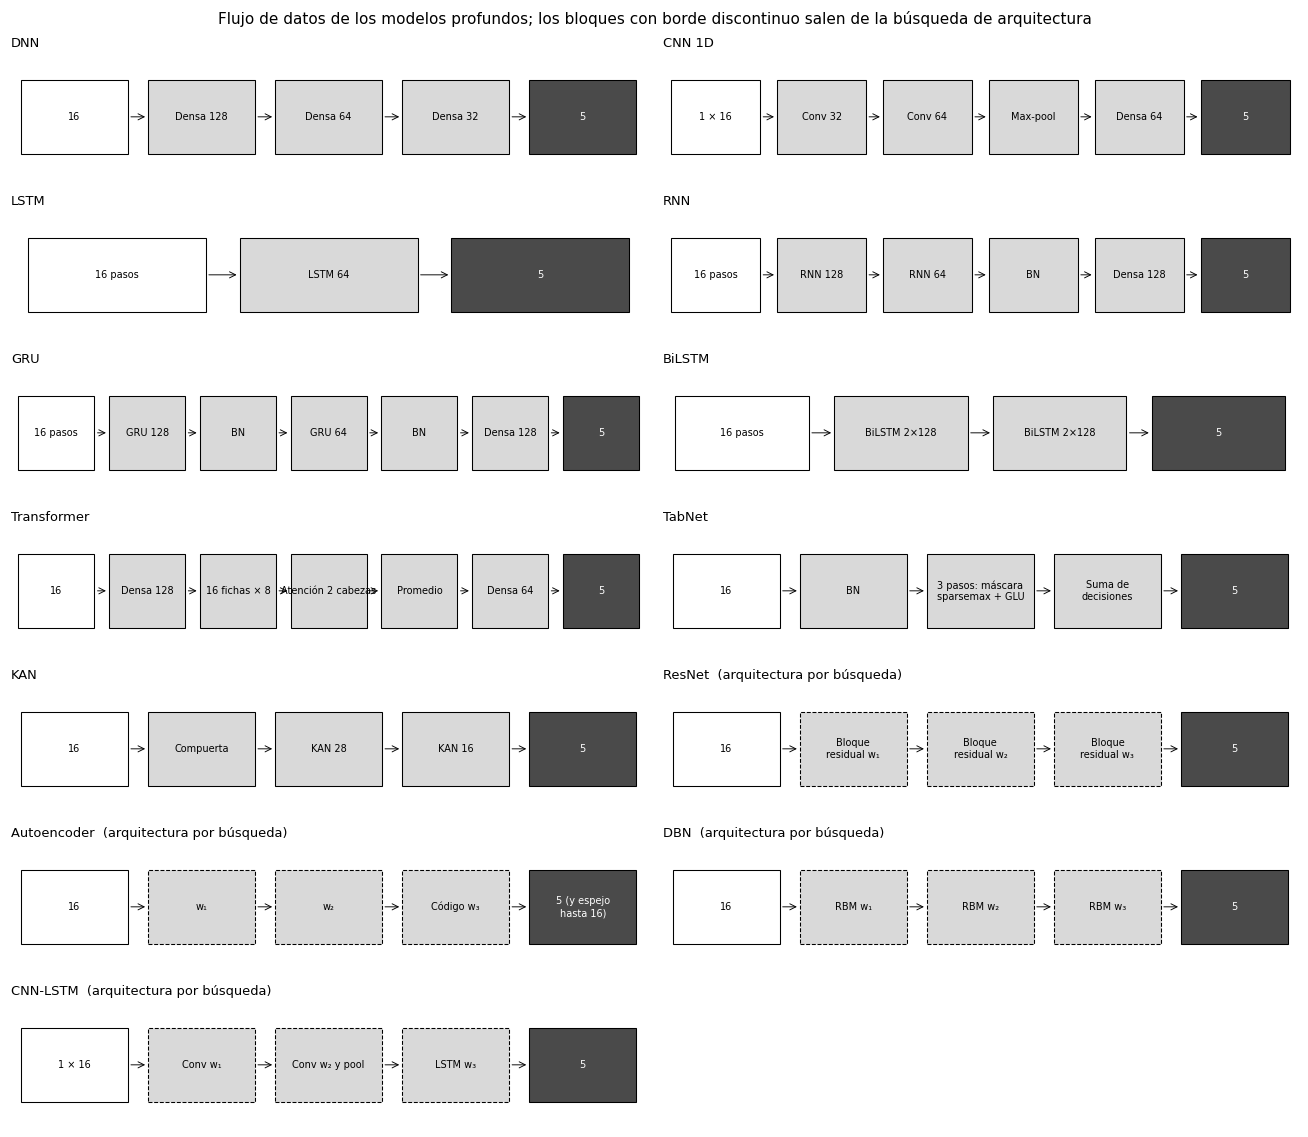

Modelo,Familia,Parámetros,MAC por muestra,Arquitectura,FLOPs por muestra
DNN,Perceptrón multicapa,12 677,12 448,Definida en la literatura,24 896
CNN 1D,Convolucional,39 493,132 928,Definida en la literatura,265 856
LSTM,Recurrente,17 477,266 560,Definida en la literatura,533 120
CNN-LSTM,Híbrida,46 213,462 144,"Búsqueda (referencia 64, 64, 64)",924 288
Autoencoder,Codificador-decodificador,19 093,9 536,"Búsqueda (referencia 64, 64, 64)",19 072
RNN,Recurrente,38 277,469 632,Definida en la literatura,939 264
Transformer,Atención,3 381,11 072,Definida en la literatura,22 144
BiLSTM,Recurrente,530 693,8 406 272,Definida en la literatura,16 812 544
ResNet,Residual,24 005,22 848,"Búsqueda (referencia 64, 64, 64)",45 696
GRU,Recurrente,96 901,1 391 232,Definida en la literatura,2 782 464


In [21]:
DIAGRAMAS = {
    "DNN": ["16", "Densa 128", "Densa 64", "Densa 32", "5"],
    "CNN 1D": ["1 × 16", "Conv 32", "Conv 64", "Max-pool", "Densa 64", "5"],
    "LSTM": ["16 pasos", "LSTM 64", "5"],
    "RNN": ["16 pasos", "RNN 128", "RNN 64", "BN", "Densa 128", "5"],
    "GRU": ["16 pasos", "GRU 128", "BN", "GRU 64", "BN", "Densa 128", "5"],
    "BiLSTM": ["16 pasos", "BiLSTM 2×128", "BiLSTM 2×128", "5"],
    "Transformer": ["16", "Densa 128", "16 fichas × 8", "Atención 2 cabezas", "Promedio", "Densa 64", "5"],
    "TabNet": ["16", "BN", "3 pasos: máscara\nsparsemax + GLU", "Suma de\ndecisiones", "5"],
    "KAN": ["16", "Compuerta", "KAN 28", "KAN 16", "5"],
    "ResNet": ["16", "Bloque\nresidual w₁", "Bloque\nresidual w₂", "Bloque\nresidual w₃", "5"],
    "Autoencoder": ["16", "w₁", "w₂", "Código w₃", "5 (y espejo\nhasta 16)"],
    "DBN": ["16", "RBM w₁", "RBM w₂", "RBM w₃", "5"],
    "CNN-LSTM": ["1 × 16", "Conv w₁", "Conv w₂ y pool", "LSTM w₃", "5"],
}
fig, ejes = plt.subplots(7, 2, figsize=(12, 10.5))
for eje, (nombre, bloques_d) in zip(ejes.ravel(), DIAGRAMAS.items()):
    eje.axis("off")
    eje.set(xlim=(0, len(bloques_d)), ylim=(0, 1))
    for i, b in enumerate(bloques_d):
        relleno = GRIS_OSCURO if i == len(bloques_d) - 1 else ("white" if i == 0 else GRIS_CLARO)
        eje.add_patch(plt.Rectangle((i + 0.08, 0.2), 0.84, 0.6, facecolor=relleno, edgecolor=NEGRO, lw=0.7, ls="--" if "w" in b else "-"))
        eje.text(i + 0.5, 0.5, b, ha="center", va="center", fontsize=6.4, color="white" if i == len(bloques_d) - 1 else NEGRO)
        if i:
            eje.annotate("", xy=(i + 0.08, 0.5), xytext=(i - 0.08, 0.5), arrowprops=dict(arrowstyle="->", lw=0.6))
    eje.set_title(nombre + ("  (arquitectura por búsqueda)" if MOD.CATALOGO[nombre]["busqueda"] else ""), fontsize=8.5, loc="left")
ejes.ravel()[-1].axis("off")
fig.suptitle("Flujo de datos de los modelos profundos; los bloques con borde discontinuo salen de la búsqueda de arquitectura", fontsize=10)
plt.tight_layout()
plt.show()
complejidad_modelos = []
for nombre in CONFIG["modelos"]["base_e1"] + CONFIG["modelos"]["top10"]:
    m = MOD.construir(nombre)
    complejidad_modelos.append({"Modelo": nombre, "Familia": MOD.CATALOGO[nombre]["familia"], "Parámetros": MOD.parametros(m), "MAC por muestra": MOD.contar_mac(m),
                                "Arquitectura": "Búsqueda (referencia 64, 64, 64)" if MOD.CATALOGO[nombre]["busqueda"] else "Definida en la literatura"})
complejidad_modelos = pd.DataFrame(complejidad_modelos)
complejidad_modelos["FLOPs por muestra"] = 2 * complejidad_modelos["MAC por muestra"]
tabla(complejidad_modelos, {"Parámetros": "{:,.0f}", "MAC por muestra": "{:,.0f}", "FLOPs por muestra": "{:,.0f}"})

In [22]:
def evidencia(familia):
    '''Estudios incluidos que usan la familia, con sus datos, valores reportados, dispersión y prueba, y el sesgo de reporte.'''
    lista = [e for e in sorted(EXT, key=lambda e: cita_base(e["doi"]).lower()) if familia in [m.strip() for m in e["modelos"].split(";")]]
    filas = [{"Estudio": citar(e["doi"]), "Dataset": e["dataset"], "Valores reportados": e["valores"], "Dispersión": e["dispersion"], "Prueba": e["prueba"]} for e in lista]
    with pd.option_context("display.max_colwidth", 120):
        tabla(pd.DataFrame(filas))
    aleatoria = sum(not agrupa(e["particion"]) and e["particion"] != "no identificada" for e in lista)
    sin_rep = sum(e["repeticiones"] == "no reportadas" for e in lista)
    publicadas = sum(REPRO[e["doi"]]["baselines_ajustados"] == "no" for e in lista)
    interpretar(f"**Sesgo de reporte.** De los {len(lista)} estudios que usan la familia, {aleatoria} parten sin agrupar filas relacionadas, {sin_rep} no reportan repeticiones, "
                f"{sum(e['dispersion'] == 'sí' for e in lista)} reportan dispersión, {sum(not e['prueba'].startswith('ninguna') for e in lista)} aplican alguna prueba y {publicadas} comparan con cifras publicadas. "
                + ("Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables." if publicadas or sin_rep == len(lista) else ""))

### Modelo 1: CNN-LSTM

- **Referencias.** Fundacional: Donahue et al. (2015), que combinan convoluciones y LSTM en una red entrenada de extremo a extremo (*long-term recurrent convolutional networks*). En el problema la usan Alharthi (2024), Alruwaili y Tunc (2026), Arulalan et al. (2023), Hamad et al. (2025), Mohamed et al. (2026), en su variante CNN-GRU, y SureshBabu y Geetha (2026), como ConvLSTM.
- **Tipo y familia.** Híbrida convolucional y recurrente.
- **Descripción técnica.** Dos convoluciones 1D extraen patrones locales del vector de 16 atributos, $z^{(l)} = \mathrm{ReLU}(W^{(l)} * z^{(l-1)} + b^{(l)})$, un *max-pooling* reduce la secuencia a 8 posiciones y una LSTM la recorre con las compuertas $i_t, f_t, o_t = \sigma(W x_t + U h_{t-1} + b)$, la memoria $c_t = f_t \odot c_{t-1} + i_t \odot \tanh(W_c x_t + U_c h_{t-1} + b_c)$ y el estado $h_t = o_t \odot \tanh(c_t)$; la salida softmax usa el último estado. El flujo es 1 × 16 → $w_1$ filtros → $w_2$ filtros → 8 pasos → $w_3$ unidades → 5.
- **Innovación.** Separa la extracción de rasgos locales, que hace la convolución con pesos compartidos, del modelado de dependencias a lo largo de la secuencia, que hace la LSTM.
- **Fortalezas y limitaciones.** Combina dos sesgos inductivos y es la familia híbrida más usada en la literatura del problema. Sin embargo, ambos sesgos suponen que el orden de las columnas tiene significado, que en una tabla es arbitrario; además, la recurrencia no se paraleliza a lo largo de la secuencia y suma hiperparámetros.
- **Complejidad.** Parámetros $P = 4 w_1 + (3 w_1 + 1) w_2 + 4[(w_2 + w_3) w_3 + 2 w_3] + 5 (w_3 + 1)$; costo por muestra de orden $\mathcal{O}(L k\, w_1 w_2 + T\, 4 (w_2 + w_3) w_3)$, con $L = 16$, $k = 3$ y $T = 8$. Los estudios no reportan un tiempo de entrenamiento comparable.
- **Definición de la arquitectura.** No está definida: Katib et al. (2025) reportan capas LSTM de 128 y 64 unidades, pero no los filtros de la convolución, y los demás estudios no la describen. Por eso se aplica la búsqueda de la sección 14 del enunciado, con la correspondencia aproximada de bloques convolucionales y recurrente.

In [23]:
evidencia("CNN-LSTM")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Alharthi (2024),"KDD Cup 99, NSL-KDD, WSN-DS y CICIDS","Exactitud en una de las tablas: CNN 89,10 %, LSTM 92,25 %, CNN-LSTM 95,11 %; propuesto 99,99 %",no,t de Student entre los dos mejores
Alruwaili y Tunc (2026),UNSW-NB15 y Edge-IIoT,"Mejora de exactitud de 0,83 a 4,98 % en UNSW-NB15",no,ninguna
Arulalan et al. (2023),CICIDS2017,No se pudieron asociar las cifras a cada modelo en el texto,no,ninguna
Hamad et al. (2025),CIC-IDS 2017,"Exactitud: CNN-GRU 98,73 %, LSTM-CNN 99,21 %; propuesto: F1 99,28 %",no,ninguna
Mohamed et al. (2026),"UAVIDS-2025, UNSW-NB15 y ET-BERT","F1 en UAVIDS-2025: AD-GNN 0,962 ± 0,003, TodyNet 0,941",sí,"p < 0,01, sin nombrar la prueba en los pasajes revisados"
SureshBabu y Geetha (2026),UAVIDS-2025,"Exactitud: ANN-GA 91,8 %, ConvLSTM 95,3 %; propuesto 98,7 %",no,ninguna


**Sesgo de reporte.** De los 6 estudios que usan la familia, 4 parten sin agrupar filas relacionadas, 6 no reportan repeticiones, 1 reportan dispersión, 2 aplican alguna prueba y 2 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

### Modelo 2: Autoencoder

- **Referencias.** Fundacional: Hinton y Salakhutdinov (2006). En el problema lo usan como referencia Balgoon (2026), Gharami y Moni (2025), como MLP-AE, Mohamed et al. (2026), como DAE, y Wu et al. (2024), como SNDA; Alissa et al. (2022) y Negm et al. (2024) proponen detectores basados en un autoencoder profundo.
- **Tipo y familia.** Codificador-decodificador.
- **Descripción técnica.** Un codificador $h = f_\phi(\mathbf{x})$ comprime los 16 atributos en un código de dimensión $w_3$ y un decodificador $\hat{\mathbf{x}} = g_\psi(h)$ lo reconstruye. Aquí se implementa como autoencoder supervisado: una cabeza softmax clasifica a partir del código y la pérdida suma la entropía cruzada ponderada y la reconstrucción, $\mathcal{L} = \mathcal{L}_{CE} + \lambda \lVert \mathbf{x} - \hat{\mathbf{x}} \rVert^2$, con λ = 1, de modo que el código debe a la vez separar las clases y conservar la información del flujo.
- **Innovación.** La reconstrucción actúa como un regularizador no supervisado que obliga a la representación a describir el tráfico, no solo a separar las etiquetas.
- **Fortalezas y limitaciones.** No supone ningún orden entre atributos y es barato. Sin embargo, la ponderación λ entre ambas pérdidas es un hiperparámetro más, y en la literatura el autoencoder suele usarse para extraer rasgos que luego clasifica otro modelo, de modo que la variante supervisada es una adaptación declarada.
- **Complejidad.** Con anchos $(w_1, w_2, w_3)$, el codificador tiene $\sum_l (w_{l-1} + 1) w_l$ parámetros con $w_0 = 16$, el decodificador es su espejo y la cabeza suma $5 (w_3 + 1)$; la inferencia solo usa el codificador y la cabeza, $\mathcal{O}(\sum_l w_{l-1} w_l)$.
- **Definición de la arquitectura.** No está definida: Alissa et al. (2022) describen la forma $n \to 2h \to h \to 2h \to n$ sin fijar $h$. Se aplica la búsqueda de la sección 14, con el decodificador espejo.

In [24]:
evidencia("Autoencoder")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Balgoon (2026),UAVIDS-2025 y T-ITS,"F1 macro: BiLSTM 77,87 %, GNN 94,60 %; propuesto 98,18 %",no,ninguna
Gharami y Moni (2025),"UAV IDS, UKM IDS y otros","Exactitud en UAV IDS: FFCNN 99,99 %, MLP-AE 98,81 %; propuesto 99,99 %",no,ninguna
Mohamed et al. (2026),"UAVIDS-2025, UNSW-NB15 y ET-BERT","F1 en UAVIDS-2025: AD-GNN 0,962 ± 0,003, TodyNet 0,941",sí,"p < 0,01, sin nombrar la prueba en los pasajes revisados"
Wu et al. (2024),CSE-CIC-IDS2018 y CIC-DDoS2019,El propuesto alcanza 99 % de exactitud en CIC-DDoS2019; las tablas de comparación no se pudieron extraer,no,ninguna


**Sesgo de reporte.** De los 4 estudios que usan la familia, 4 parten sin agrupar filas relacionadas, 4 no reportan repeticiones, 1 reportan dispersión, 1 aplican alguna prueba y 0 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

### Modelo 3: RNN

- **Referencias.** Fundacional: Elman (1990). La arquitectura se toma de Biswas et al. (2026), que la usan como línea base en drones; también la usan Abbas et al. (2026), Ashraf et al. (2023), Li et al. (2026b) y Wang et al. (2026).
- **Tipo y familia.** Recurrente simple.
- **Descripción técnica.** En cada paso, $h_t = \mathrm{ReLU}(W_x x_t + W_h h_{t-1} + b)$. Biswas et al. (2026) apilan dos capas, de 128 unidades, que devuelve la secuencia, y de 64, seguidas de normalización por lotes, *dropout* de 0,3 y una densa de 128 con ReLU antes de la salida. El flujo es 16 pasos de un valor → 128 → 64 → 128 → 5.
- **Innovación.** Introduce un estado que se arrastra a lo largo de la secuencia, la idea que después refinan la LSTM y la GRU con compuertas.
- **Fortalezas y limitaciones.** Tiene menos parámetros por unidad que la LSTM y la GRU. Sin embargo, sin compuertas sufre el desvanecimiento o la explosión del gradiente (Bengio et al., 1994), en especial con ReLU, que no acota el estado, y supone un orden entre atributos.
- **Complejidad.** $P = \sum_l (d_{l-1} + h_l + 1) h_l$ más la cabeza; costo de orden $\mathcal{O}(T\, h^2)$ por capa, con $T = 16$, sin paralelismo a lo largo de los pasos.
- **Definición de la arquitectura.** Definida por Biswas et al. (2026); no aplica la búsqueda.

In [25]:
evidencia("RNN")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Abbas et al. (2026),UAVIDS-2025,"Precisión en Wormhole: FL-CNN 0,70, FL-RNN 0,78, FL-MLP 0,78 y FL-GCN 0,81; en Blackhole: 0,90, 0,92, 0,94 y 0,92",no,ninguna
Ashraf et al. (2023),CICIDS2017 y otros,"Exactitud: Bi-LSTM 91,36 %, LSTM 91,00 %, RNN 90,16 %, GRU 89,13 %, perceptrón 85,02 %",no,ninguna
Biswas et al. (2026),ISOT Drone Anomaly Detection,"Exactitud del propuesto: 99,99 %",sí,ninguna
Li et al. (2026b),UAV-NIDD y CICIoT2022,"F1 en UAV-NIDD: TGE-ETD 99,97 ± 0,04 %, YaTC 99,96 ± 0,77 %, FNN 95,20 %, TFE-GNN 93,01 ± 2,14 %, MAML 71,09 %",sí,ninguna
Wang et al. (2026),UAVIDS-2025,"LSTM de dos capas: F1 98,60 %; propuesto: exactitud 99,68 ± 0,12 %",sí,t de Student pareada


**Sesgo de reporte.** De los 5 estudios que usan la familia, 3 parten sin agrupar filas relacionadas, 2 no reportan repeticiones, 3 reportan dispersión, 1 aplican alguna prueba y 0 comparan con cifras publicadas. 

### Modelo 4: Transformer (TSLT-Net)

- **Referencias.** Fundacional: Vaswani et al. (2017). La arquitectura es TSLT-Net, de Biswas et al. (2026), un Transformer ligero para detectar intrusiones en drones, con su configuración capa a capa en su tabla 1. En el problema usan Transformers Alshamrani y Alghamdi (2026), con FlowTransformer, Li et al. (2026b) y Zhou et al. (2026).
- **Tipo y familia.** Basada en atención.
- **Descripción técnica.** Una densa de 128 con ReLU proyecta el flujo, que se reorganiza en 16 fichas de dimensión 8, se normaliza con LayerNorm y pasa por una atención multicabeza, $\mathrm{Atención}(Q, K, V) = \mathrm{softmax}(Q K^\top / \sqrt{d_k}) V$, con 2 cabezas y $d_k = 4$; luego, un promedio global, una densa de 64 con ReLU, *dropout* de 0,3 y la salida. Biswas et al. (2026) aclaran que las 16 fichas no son pasos de tiempo, sino combinaciones aprendidas de atributos.
- **Innovación.** La atención pondera las interacciones entre fichas según el propio ejemplo, en lugar de fijarlas en los pesos.
- **Fortalezas y limitaciones.** No depende del orden de las columnas, porque la primera densa mezcla todos los atributos, y es muy liviano. Sin embargo, la atención sobre fichas aprendidas es difícil de interpretar, y no tiene conexión residual ni red *feed-forward*, a diferencia del Transformer original.
- **Complejidad.** $\mathcal{O}(n^2 d)$ en la atención, con $n = 16$ fichas y $d = 8$, más $\mathcal{O}(16 \cdot 128)$ en la proyección.
- **Definición de la arquitectura.** Definida por Biswas et al. (2026); no aplica la búsqueda.

In [26]:
evidencia("Transformer")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Alshamrani y Alghamdi (2026),UAV-NIDD,"F1 supervisado: LSTM 94,5 ± 0,7 % y FlowTransformer 95,8 ± 0,6 %; propuesto 85,6 ± 0,8 % sin haber visto el ataque",sí,"t pareada, p < 0,001"
Li et al. (2026b),UAV-NIDD y CICIoT2022,"F1 en UAV-NIDD: TGE-ETD 99,97 ± 0,04 %, YaTC 99,96 ± 0,77 %, FNN 95,20 %, TFE-GNN 93,01 ± 2,14 %, MAML 71,09 %",sí,ninguna
Zhou et al. (2026),"ISCXVPN2016, CICIDS-2018, TON IoT y CIC IoT 2023","Exactitud en ISCXVPN2016: LSTM 95,9 %, CNN 94,95 %",no,ninguna


**Sesgo de reporte.** De los 3 estudios que usan la familia, 3 parten sin agrupar filas relacionadas, 1 no reportan repeticiones, 2 reportan dispersión, 1 aplican alguna prueba y 0 comparan con cifras publicadas. 

### Modelo 5: BiLSTM

- **Referencias.** Fundacional: Graves y Schmidhuber (2005). La arquitectura se toma de Balgoon (2026), que reporta su BiLSTM como línea base en UAVIDS-2025; también la usan Ashraf et al. (2023) y Wang et al. (2026).
- **Tipo y familia.** Recurrente bidireccional.
- **Descripción técnica.** Dos LSTM recorren la secuencia en sentidos opuestos y su estado se concatena, $h_t = [\overrightarrow{h}_t; \overleftarrow{h}_t]$, con las compuertas de la LSTM. Balgoon (2026) usa dos capas de 128 unidades por dirección con *dropout* de 0,3; la salida concatena el último estado de cada dirección.
- **Innovación.** Cada posición ve el contexto anterior y el posterior, lo que en un vector de atributos equivale a no privilegiar un extremo de la secuencia.
- **Fortalezas y limitaciones.** Es la variante recurrente con más capacidad del Top 10. Sin embargo, es la más costosa, con cerca de 531 000 parámetros, y Balgoon (2026) reporta para ella un F1 macro de solo 77,87 % en UAVIDS-2025.
- **Complejidad.** $\mathcal{O}(2\, T\, 4 (d + h) h)$ por capa, con $T = 16$ y $h = 128$.
- **Definición de la arquitectura.** Definida por Balgoon (2026), donde es un componente de su modelo propuesto evaluado también por separado; no aplica la búsqueda.

In [27]:
evidencia("BiLSTM")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Ashraf et al. (2023),CICIDS2017 y otros,"Exactitud: Bi-LSTM 91,36 %, LSTM 91,00 %, RNN 90,16 %, GRU 89,13 %, perceptrón 85,02 %",no,ninguna
Balgoon (2026),UAVIDS-2025 y T-ITS,"F1 macro: BiLSTM 77,87 %, GNN 94,60 %; propuesto 98,18 %",no,ninguna
Wang et al. (2026),UAVIDS-2025,"LSTM de dos capas: F1 98,60 %; propuesto: exactitud 99,68 ± 0,12 %",sí,t de Student pareada


**Sesgo de reporte.** De los 3 estudios que usan la familia, 3 parten sin agrupar filas relacionadas, 2 no reportan repeticiones, 1 reportan dispersión, 1 aplican alguna prueba y 0 comparan con cifras publicadas. 

### Modelo 6: ResNet

- **Referencias.** Fundacional: He et al. (2016). En el problema la usan Hakeem et al. (2025) y Katib et al. (2025), en ambos casos como red convolucional para imágenes adaptada a otros datos; para tablas, Gorishniy et al. (2021) proponen la variante residual densa que aquí se implementa.
- **Tipo y familia.** Residual.
- **Descripción técnica.** Cada bloque aprende un residuo sobre su entrada, $\mathbf{z}_{l} = \mathrm{ReLU}(F(\mathbf{z}_{l-1}) + S \mathbf{z}_{l-1})$, con $F$ = densa, normalización, ReLU, densa y normalización, y $S$ la identidad o una proyección lineal si cambia el ancho; 3 bloques de anchos $(w_1, w_2, w_3)$ y la salida.
- **Innovación.** El atajo de identidad permite entrenar redes profundas sin degradación, porque el gradiente fluye por él aunque $F$ se sature.
- **Fortalezas y limitaciones.** No supone orden entre atributos y es estable de entrenar. Sin embargo, en tablas de 16 columnas la profundidad aporta poco, y en datos tabulares su ventaja frente a un perceptrón depende del conjunto (Gorishniy et al., 2021).
- **Complejidad.** $\mathcal{O}(\sum_l w_{l-1} w_l + w_l^2)$ por muestra.
- **Definición de la arquitectura.** No está definida en la literatura del problema; se aplica la búsqueda de la sección 14, con el ancho de cada bloque residual.

In [28]:
evidencia("ResNet")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Hakeem et al. (2025),datos ciberfísicos de GPS,"Exactitud: ResNet 90,99 %, MLP 89,49 %, CNN 86,36 %, LSTM 82,45 %",no,ninguna
Katib et al. (2025),InSDN,"Exactitud del propuesto: 99,88 %",no,ninguna


**Sesgo de reporte.** De los 2 estudios que usan la familia, 2 parten sin agrupar filas relacionadas, 2 no reportan repeticiones, 0 reportan dispersión, 0 aplican alguna prueba y 1 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

### Modelo 7: GRU

- **Referencias.** Fundacional: Cho et al. (2014). La arquitectura se toma de Biswas et al. (2026); también la usan Aburasain (2024), Ashraf et al. (2023), Attaullah et al. (2026b) y Hamad et al. (2025).
- **Tipo y familia.** Recurrente con compuertas.
- **Descripción técnica.** La compuerta de actualización $z_t = \sigma(W_z x_t + U_z h_{t-1})$ y la de reinicio $r_t = \sigma(W_r x_t + U_r h_{t-1})$ combinan el estado anterior con el candidato $\tilde{h}_t = \tanh(W x_t + U (r_t \odot h_{t-1}))$ en $h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$. Biswas et al. (2026) apilan GRU de 128 y de 64, cada una con normalización por lotes y *dropout* de 0,3, y una densa de 128 antes de la salida.
- **Innovación.** Logra un control del flujo del gradiente parecido al de la LSTM con dos compuertas en lugar de tres y sin celda de memoria aparte.
- **Fortalezas y limitaciones.** Es más estable que la RNN simple. Sin embargo, supone un orden entre atributos y, con 128 unidades, es la segunda más costosa del Top 10.
- **Complejidad.** $\mathcal{O}(T\, 3 (d + h) h)$ por capa.
- **Definición de la arquitectura.** Definida por Biswas et al. (2026); no aplica la búsqueda.

In [29]:
evidencia("GRU")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Aburasain (2024),ToN-IoT y Edge-IIoTset,"Exactitud: LSTM de 96,20 a 96,95 %, GRU de 96,00 a 96,50 %",no,ninguna
Ashraf et al. (2023),CICIDS2017 y otros,"Exactitud: Bi-LSTM 91,36 %, LSTM 91,00 %, RNN 90,16 %, GRU 89,13 %, perceptrón 85,02 %",no,ninguna
Attaullah et al. (2026b),conjunto multimodal de UAV,"Exactitud del propuesto: 99,49 %",no,ninguna
Biswas et al. (2026),ISOT Drone Anomaly Detection,"Exactitud del propuesto: 99,99 %",sí,ninguna
Hamad et al. (2025),CIC-IDS 2017,"Exactitud: CNN-GRU 98,73 %, LSTM-CNN 99,21 %; propuesto: F1 99,28 %",no,ninguna


**Sesgo de reporte.** De los 5 estudios que usan la familia, 3 parten sin agrupar filas relacionadas, 3 no reportan repeticiones, 1 reportan dispersión, 0 aplican alguna prueba y 2 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

### Modelo 8: KAN

- **Referencias.** Fundacional: Liu et al. (2024). La arquitectura es el clasificador de ataques de H-MicroKAN, de Bakiri et al. (2026), el único estudio del problema que la usa, sobre UAVIDS-2025 y con partición por nodo.
- **Tipo y familia.** Red de Kolmogorov-Arnold.
- **Descripción técnica.** Por el teorema de Kolmogorov-Arnold, una función continua de varias variables se escribe como composición de funciones de una variable. Una capa KAN pone una función aprendible en cada arista, $y_j = \sum_i \varphi_{ij}(x_i)$, y aquí cada $\varphi_{ij}(x) = \sum_{k=1}^{K} w_{ijk}\, \exp(-((x - \mu_k)/h)^2)$ usa $K = 5$ bases gaussianas fijas en [−5, 5], la formulación FastKAN que adoptan Bakiri et al. (2026). La red aplica una compuerta $\mathbf{x} \odot \sigma(W_2 \mathrm{ReLU}(W_1 \mathbf{x}))$, dos capas KAN de 28 y 16 neuronas con normalización, GELU y *dropout* de 0,25 y 0,20, y la salida.
- **Innovación.** Traslada la no linealidad de los nodos a las aristas, lo que da fronteras flexibles con pocos parámetros y funciones de cada atributo que se pueden graficar.
- **Fortalezas y limitaciones.** Es el modelo más liviano del Top 10 después del Transformer y se diseñó para microcontroladores. Sin embargo, el recorte en [−5, 5] trunca los valores extremos, y Bakiri et al. (2026) lo usan como la segunda etapa de un clasificador jerárquico, de modo que aplicarlo directamente a las 5 clases es una adaptación declarada.
- **Complejidad.** $n_{in} n_{out} K + n_{out}$ parámetros por capa, la fórmula que publican sus autores; costo $\mathcal{O}(n_{in} n_{out} K)$.
- **Definición de la arquitectura.** Definida por Bakiri et al. (2026), en su tabla 2; no aplica la búsqueda.

In [30]:
evidencia("KAN")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Bakiri et al. (2026),UAVIDS-2025 y UAV-NIDD,"Exactitud en cinco clases en UAVIDS-2025: 92,50 %; KAN plana 93,35 %",no,ninguna


**Sesgo de reporte.** De los 1 estudios que usan la familia, 0 parten sin agrupar filas relacionadas, 1 no reportan repeticiones, 0 reportan dispersión, 0 aplican alguna prueba y 0 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

### Modelo 9: TabNet

- **Referencias.** Fundacional: Arik y Pfister (2021). En el problema lo usan Hadi et al. (2026), como segunda etapa de un detector en tres niveles.
- **Tipo y familia.** Atención secuencial para datos tabulares.
- **Descripción técnica.** En cada paso de decisión, un transformador atento elige qué atributos mirar con una máscara $M[i] = \mathrm{sparsemax}(P[i-1] \cdot h_i(a[i-1]))$, donde $P[i-1]$ penaliza reutilizar atributos ya elegidos con el factor γ, y un transformador de atributos con bloques GLU procesa $M[i] \odot \mathbf{x}$; la salida suma las decisiones de los pasos. La pérdida agrega una regularización de dispersión de las máscaras.
- **Innovación.** La selección de atributos es por ejemplo e interpretable, porque las máscaras indican qué atributos usó cada decisión.
- **Fortalezas y limitaciones.** Fue diseñado para tablas y no supone orden entre columnas. Sin embargo, es sensible a sus hiperparámetros, la normalización por lotes fantasma depende del tamaño del lote, y en la comparación de Gorishniy et al. (2021) no supera de forma consistente a otros modelos ni a los árboles potenciados.
- **Complejidad.** $\mathcal{O}(N_{steps}\, (d\, n_a + (n_d + n_a)^2))$ por muestra.
- **Definición de la arquitectura.** El artículo define los bloques y su número, y se usa la configuración por defecto de la implementación de referencia, pytorch-tabnet: $n_d = n_a = 8$, 3 pasos, γ = 1,3 y λ de dispersión de 10⁻³. No aplica la búsqueda.

In [31]:
evidencia("TabNet")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Hadi et al. (2026),GCS-NIDD,"Exactitud por modelo: TabNet 93,10 %, LightGBM 90,20 %, BLS 89,70 %; fusión 99,30 %",no,ninguna


**Sesgo de reporte.** De los 1 estudios que usan la familia, 0 parten sin agrupar filas relacionadas, 1 no reportan repeticiones, 0 reportan dispersión, 0 aplican alguna prueba y 0 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

### Modelo 10: DBN

- **Referencias.** Fundacional: Hinton et al. (2006). En el problema la usan como referencia Alotaibi et al. (2024), Babu et al. (2024) y Negm et al. (2024), como IDBN y DPC-DBN, y Tan et al. (2019) proponen una DBN optimizada con PSO.
- **Tipo y familia.** Generativa preentrenada capa a capa.
- **Descripción técnica.** Una pila de máquinas de Boltzmann restringidas, cada una con energía $E(\mathbf{v}, \mathbf{h}) = -\mathbf{b}^\top \mathbf{v} - \mathbf{c}^\top \mathbf{h} - \mathbf{h}^\top W \mathbf{v}$ (la primera con unidades visibles gaussianas), se preentrena sin etiquetas con divergencia contrastiva de un paso, $\Delta W \propto \langle \mathbf{h} \mathbf{v}^\top \rangle_{datos} - \langle \mathbf{h} \mathbf{v}^\top \rangle_{1}$, y luego se ajusta con la entropía cruzada como un perceptrón con sigmoides.
- **Innovación.** Fue el primer método que permitió entrenar redes profundas, al inicializar los pesos con una representación generativa en lugar de valores aleatorios.
- **Fortalezas y limitaciones.** El preentrenamiento puede ayudar con pocos datos etiquetados. Sin embargo, con optimizadores modernos y decenas de miles de ejemplos su ventaja suele desaparecer, y ningún estudio de 2025 o 2026 la usa, lo que muestra que la familia está en retirada.
- **Complejidad.** $\mathcal{O}(\sum_l w_{l-1} w_l)$ por muestra en inferencia, más el preentrenamiento, de orden $\mathcal{O}(E\, n \sum_l w_{l-1} w_l)$ con $E$ épocas por RBM.
- **Definición de la arquitectura.** No está definida: Tan et al. (2019) la optimizan con PSO para KDD Cup 99, sin una configuración aplicable a estos datos en los pasajes revisados, y los demás estudios la toman de otros trabajos. Se aplica la búsqueda de la sección 14, con las unidades de cada RBM.

In [32]:
evidencia("DBN")

Estudio,Dataset,Valores reportados,Dispersión,Prueba
Alotaibi et al. (2024),no identificado,"Exactitud: IDBN 95,32 %, DPC-DBN 94,39 %",no,ninguna
Babu et al. (2024),no identificado,"Exactitud: IDBN 95,32 %, DPC-DBN 94,39 %; propuesto 99,63 %",no,ninguna
Negm et al. (2024),NSL-KDD,"Exactitud: propuesto 99,36 %, IDBN 95,32 %, DPC-DBN 94,39 %",no,ninguna


**Sesgo de reporte.** De los 3 estudios que usan la familia, 3 parten sin agrupar filas relacionadas, 3 no reportan repeticiones, 0 reportan dispersión, 0 aplican alguna prueba y 1 comparan con cifras publicadas. Ningún estudio de la familia ajusta sus líneas base con un presupuesto equivalente, de modo que las ventajas publicadas no son comparables.

(sec-3-4)=
## 3.4 Comparación crítica y *gap* de investigación

**Matriz comparativa.** La matriz reúne, para los diez modelos, la familia, los parámetros y FLOPs de la implementación de este entregable, los datos que requiere, el mejor valor que reporta la literatura del problema y la fortaleza y la limitación principales. Los valores de la literatura no se comparan entre sí, porque provienen de conjuntos de datos y protocolos distintos.

In [33]:
MATRIZ_CUALITATIVA = {
    "CNN-LSTM": ("Secuencia de atributos", "Rasgos locales y dependencias en un solo modelo", "Supone un orden de columnas arbitrario"),
    "Autoencoder": ("Vector, sin orden", "La reconstrucción regulariza la representación", "Un hiperparámetro más (λ)"),
    "RNN": ("Secuencia de atributos", "Pocos parámetros por unidad", "Gradiente inestable sin compuertas"),
    "Transformer": ("Vector, sin orden", "Muy liviano; atención por ejemplo", "Fichas aprendidas difíciles de interpretar"),
    "BiLSTM": ("Secuencia de atributos", "Contexto en ambos sentidos", "El más costoso del Top 10"),
    "ResNet": ("Vector, sin orden", "Entrenamiento estable", "Profundidad poco útil con 16 columnas"),
    "GRU": ("Secuencia de atributos", "Control del gradiente con dos compuertas", "Costosa y dependiente del orden"),
    "KAN": ("Vector acotado en [−5, 5]", "Liviana; funciones por atributo graficables", "Trunca valores extremos"),
    "TabNet": ("Vector, sin orden", "Selección de atributos interpretable", "Sensible a hiperparámetros y al lote"),
    "DBN": ("Vector, sin orden", "Preentrenamiento sin etiquetas", "Familia en retirada; costo de preentrenar"),
}
filas_m = []
for _, f in complejidad_modelos[complejidad_modelos["Modelo"].isin(MATRIZ_CUALITATIVA)].iterrows():
    entrada, fuerte, debil = MATRIZ_CUALITATIVA[f["Modelo"]]
    filas_m.append({"Modelo": f["Modelo"], "Familia": f["Familia"], "Parámetros": f["Parámetros"], "FLOPs por muestra": f["FLOPs por muestra"], "Entrada que requiere": entrada,
                    "Estudios": int(puntaje.loc[puntaje["modelo"] == f["Modelo"], "estudios"].item()), "Con UAVIDS-2025": int(puntaje.loc[puntaje["modelo"] == f["Modelo"], "estudios_uavids"].item()),
                    "Fortaleza": fuerte, "Limitación": debil})
tabla(pd.DataFrame(filas_m), {"Parámetros": "{:,.0f}", "FLOPs por muestra": "{:,.0f}"})
anios = pd.DataFrame([{"anio": int(e["anio"]), "familia": m.strip()} for e in EXT for m in e["modelos"].split(";") if m.strip()])
tendencia = anios.assign(periodo=np.where(anios["anio"] >= 2025, "2025–2026", "2019–2024")).groupby(["familia", "periodo"]).size().unstack(fill_value=0)
estudios_periodo = pd.Series([int(e["anio"]) >= 2025 for e in EXT]).map({True: "2025–2026", False: "2019–2024"}).value_counts()
tendencia_pct = (100 * tendencia / estudios_periodo).round(1)
tabla(tendencia_pct.loc[["DNN/MLP", "CNN", "LSTM", "CNN-LSTM", "GRU", "Transformer", "GNN", "KAN", "TabNet", "DBN", "Autoencoder"]].reset_index(names="Familia"),
      {c: "{:.1f}" for c in tendencia_pct.columns})
interpretar(f'''**Interpretación.** En los {estudios_periodo["2019–2024"]} estudios de 2019 a 2024 y los {estudios_periodo["2025–2026"]} de 2025 a 2026, la proporción que usa Transformers pasa de {num(tendencia_pct.loc["Transformer", "2019–2024"], 1)} % a {num(tendencia_pct.loc["Transformer", "2025–2026"], 1)} %, la de GNN de {num(tendencia_pct.loc["GNN", "2019–2024"], 1)} % a {num(tendencia_pct.loc["GNN", "2025–2026"], 1)} %, y KAN y TabNet aparecen solo en el periodo reciente, mientras que la DBN pasa de {num(tendencia_pct.loc["DBN", "2019–2024"], 1)} % a {num(tendencia_pct.loc["DBN", "2025–2026"], 1)} %. En costo, la matriz va de unos 3400 parámetros en el Transformer a más de medio millón en la BiLSTM.

Así mismo, la tendencia es clara hacia la atención, los grafos y los modelos livianos para despliegue a bordo, con modelos híbridos y propuestos que superan a líneas base sin ajustar. En reproducibilidad, el panorama es el de la sección 3.1: un solo estudio con código público, ninguno con líneas base ajustadas con el mismo presupuesto y solo dos que agrupan las filas relacionadas al partir.

En consecuencia, se formula el *gap* sobre esas carencias, que se pueden refutar con la hoja de extracción.''')

Modelo,Familia,Parámetros,FLOPs por muestra,Entrada que requiere,Estudios,Con UAVIDS-2025,Fortaleza,Limitación
CNN-LSTM,Híbrida,46 213,924 288,Secuencia de atributos,6,2,Rasgos locales y dependencias en un solo modelo,Supone un orden de columnas arbitrario
Autoencoder,Codificador-decodificador,19 093,19 072,"Vector, sin orden",4,2,La reconstrucción regulariza la representación,Un hiperparámetro más (λ)
RNN,Recurrente,38 277,939 264,Secuencia de atributos,5,2,Pocos parámetros por unidad,Gradiente inestable sin compuertas
Transformer,Atención,3 381,22 144,"Vector, sin orden",3,0,Muy liviano; atención por ejemplo,Fichas aprendidas difíciles de interpretar
BiLSTM,Recurrente,530 693,16 812 544,Secuencia de atributos,3,2,Contexto en ambos sentidos,El más costoso del Top 10
ResNet,Residual,24 005,45 696,"Vector, sin orden",2,0,Entrenamiento estable,Profundidad poco útil con 16 columnas
GRU,Recurrente,96 901,2 782 464,Secuencia de atributos,5,0,Control del gradiente con dos compuertas,Costosa y dependiente del orden
KAN,Kolmogorov-Arnold,4 845,9 376,"Vector acotado en [−5, 5]",1,1,Liviana; funciones por atributo graficables,Trunca valores extremos
TabNet,Atención,6 728,17 232,"Vector, sin orden",1,0,Selección de atributos interpretable,Sensible a hiperparámetros y al lote
DBN,Generativa preentrenada,9 733,19 072,"Vector, sin orden",3,0,Preentrenamiento sin etiquetas,Familia en retirada; costo de preentrenar


Familia,2019–2024,2025–2026
DNN/MLP,"40,0","67,9"
CNN,"40,0","60,7"
LSTM,"40,0","28,6"
CNN-LSTM,"13,3","14,3"
GRU,"13,3","10,7"
Transformer,"0,0","10,7"
GNN,"0,0","10,7"
KAN,"0,0","3,6"
TabNet,"0,0","3,6"
DBN,"20,0","0,0"


**Interpretación.** En los 15 estudios de 2019 a 2024 y los 28 de 2025 a 2026, la proporción que usa Transformers pasa de 0,0 % a 10,7 %, la de GNN de 0,0 % a 10,7 %, y KAN y TabNet aparecen solo en el periodo reciente, mientras que la DBN pasa de 20,0 % a 0,0 %. En costo, la matriz va de unos 3400 parámetros en el Transformer a más de medio millón en la BiLSTM.

Así mismo, la tendencia es clara hacia la atención, los grafos y los modelos livianos para despliegue a bordo, con modelos híbridos y propuestos que superan a líneas base sin ajustar. En reproducibilidad, el panorama es el de la sección {ref}`3.1 <sec-3-1>`: un solo estudio con código público, ninguno con líneas base ajustadas con el mismo presupuesto y solo dos que agrupan las filas relacionadas al partir.

En consecuencia, se formula el *gap* sobre esas carencias, que se pueden refutar con la hoja de extracción.

In [34]:
SECUENCIALES = {"CNN", "LSTM", "CNN-LSTM", "RNN", "GRU", "BiLSTM"}
n_secuenciales = sum(bool(SECUENCIALES & {m.strip() for m in e["modelos"].split(";")}) for e in EXT)
uavids_ext = [e for e in EXT if "UAVIDS-2025" in e["dataset"]]
interpretar(f'''**Gap en la literatura.** Ningún estudio incluido compara diez o más arquitecturas de Deep Learning de familias distintas sobre UAVIDS-2025 con una partición que agrupe los flujos de una misma serie, con el mismo presupuesto de ajuste para todos los modelos y con inferencia estadística sobre repeticiones. La hoja de extracción permite refutarlo: de los {len(uavids_ext)} estudios que usan UAVIDS-2025, {sum(agrupa(e["particion"]) for e in uavids_ext)} agrupa las filas al partir, y lo hace por nodo y no por serie (Bakiri et al., 2026); ninguno ajusta sus líneas base con un presupuesto equivalente, {sum(not e["prueba"].startswith("ninguna") for e in uavids_ext)} aplican alguna prueba estadística y ninguno corrige por comparaciones múltiples.

**Conexión con las preguntas de investigación.** RQ1 y RQ2 responden directamente al *gap*, porque comparan el Top 10 con el baseline del Entregable 1 y con un árbol potenciado ajustado con el mismo presupuesto, bajo la partición agrupada. RQ3 pone a prueba un supuesto que la literatura da por hecho sin contrastarlo: que leer los atributos como una secuencia aporta, como hacen la CNN, la LSTM y sus variantes en {n_secuenciales} de los {len(EXT)} estudios. Si RQ3 rechaza su hipótesis nula con una diferencia negativa, buena parte de esas arquitecturas estaría imponiendo un sesgo inductivo que perjudica en datos tabulares.''')

**Gap en la literatura.** Ningún estudio incluido compara diez o más arquitecturas de Deep Learning de familias distintas sobre UAVIDS-2025 con una partición que agrupe los flujos de una misma serie, con el mismo presupuesto de ajuste para todos los modelos y con inferencia estadística sobre repeticiones. La hoja de extracción permite refutarlo: de los 12 estudios que usan UAVIDS-2025, 1 agrupa las filas al partir, y lo hace por nodo y no por serie (Bakiri et al., 2026); ninguno ajusta sus líneas base con un presupuesto equivalente, 3 aplican alguna prueba estadística y ninguno corrige por comparaciones múltiples.

**Conexión con las preguntas de investigación.** RQ1 y RQ2 responden directamente al *gap*, porque comparan el Top 10 con el baseline del Entregable 1 y con un árbol potenciado ajustado con el mismo presupuesto, bajo la partición agrupada. RQ3 pone a prueba un supuesto que la literatura da por hecho sin contrastarlo: que leer los atributos como una secuencia aporta, como hacen la CNN, la LSTM y sus variantes en 31 de los 43 estudios. Si RQ3 rechaza su hipótesis nula con una diferencia negativa, buena parte de esas arquitecturas estaría imponiendo un sesgo inductivo que perjudica en datos tabulares.